# PDX vs DFW Median Home Valuation & Growth Rate Comparison

In [475]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from scipy import stats
# Libraries used for statistical math and visualizations

In [476]:
df = pd.read_csv('city_data.csv')

In [477]:
df.head()

,RegionID,SizeRank,RegionName,RegionType,StateName,State,Metro,CountyName,2000-01-31,2000-02-29,...,2025-02-28,2025-03-31,2025-04-30,2025-05-31,2025-06-30,2025-07-31,2025-08-31,2025-09-30,2025-10-31,2025-11-30
0,6181,0,New York,city,NY,NY,"New York-Newark-Jersey City, NY-NJ-PA",Queens County,251979.044326,253330.056370,...,8.146688e+05,8.150804e+05,8.188315e+05,823011.200027,826871.534632,828571.006219,829621.839504,831933.027263,836094.865549,840926.833744
1,12447,1,Los Angeles,city,CA,CA,"Los Angeles-Long Beach-Anaheim, CA",Los Angeles County,226785.516504,227138.249765,...,1.015899e+06,1.006662e+06,1.000095e+06,994075.899578,988344.860571,985071.535518,983980.869971,986304.492560,989636.543469,994023.734086
2,39051,2,Houston,city,TX,TX,"Houston-The Woodlands-Sugar Land, TX",Harris County,104864.928826,104834.446972,...,2.747563e+05,2.738480e+05,2.726607e+05,271489.555692,270317.612810,269393.633137,268584.468866,267926.671488,267378.943088,267113.523321
3,17426,3,Chicago,city,IL,IL,"Chicago-Naperville-Elgin, IL-IN-WI",Cook County,122478.075011,122470.823365,...,2.973851e+05,2.980820e+05,2.990100e+05,299641.616910,300053.938998,300808.455157,301461.597333,302447.051730,303303.907876,304399.225648
4,6915,4,San Antonio,city,TX,TX,"San Antonio-New Braunfels, TX",Bexar County,98938.514086,99031.681309,...,2.544860e+05,2.534599e+05,2.522285e+05,250861.642444,249837.597910,249165.439422,248802.481195,248538.909811,248150.926278,247776.252914


In [478]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21444 entries, 0 to 21443
Columns: 319 entries, RegionID to 2025-11-30
dtypes: float64(311), int64(2), object(6)
memory usage: 52.2+ MB


> We can see that the full table includes 21,444 entires with 319 fields worth of descriptive data describing the individual cities. The majority of the fields in this table are median pricing data occuring over various dates. The first step of diving into this table will be cleaning it by removing the null values from interfering with analysis.

In [479]:
df_null_rows = df[df.isnull().any(axis = 1)]

df_null_rows.shape[0]

14205

In [480]:
df_cleaned = df.dropna()
df_cleaned_null_rows = df_cleaned[df_cleaned.isnull().any(axis = 1)]

In [481]:
df_cleaned_null_rows.shape[0]

0

In [482]:
df_cleaned.shape[0]

7239

> 14,205 rows of the 21,444 contained null values and have been identified as containing null values. The majority of these instances, upon visual inspection, constituted the population of smaller cities that are less useful for the attempted analysis of this report. The remaining 7,239 rows will be broken up into the respective metro areas necessary for this report and further identified.

In [483]:
df_cleaned.head()

,RegionID,SizeRank,RegionName,RegionType,StateName,State,Metro,CountyName,2000-01-31,2000-02-29,...,2025-02-28,2025-03-31,2025-04-30,2025-05-31,2025-06-30,2025-07-31,2025-08-31,2025-09-30,2025-10-31,2025-11-30
0,6181,0,New York,city,NY,NY,"New York-Newark-Jersey City, NY-NJ-PA",Queens County,251979.044326,253330.056370,...,8.146688e+05,8.150804e+05,8.188315e+05,823011.200027,826871.534632,828571.006219,829621.839504,831933.027263,836094.865549,840926.833744
1,12447,1,Los Angeles,city,CA,CA,"Los Angeles-Long Beach-Anaheim, CA",Los Angeles County,226785.516504,227138.249765,...,1.015899e+06,1.006662e+06,1.000095e+06,994075.899578,988344.860571,985071.535518,983980.869971,986304.492560,989636.543469,994023.734086
2,39051,2,Houston,city,TX,TX,"Houston-The Woodlands-Sugar Land, TX",Harris County,104864.928826,104834.446972,...,2.747563e+05,2.738480e+05,2.726607e+05,271489.555692,270317.612810,269393.633137,268584.468866,267926.671488,267378.943088,267113.523321
3,17426,3,Chicago,city,IL,IL,"Chicago-Naperville-Elgin, IL-IN-WI",Cook County,122478.075011,122470.823365,...,2.973851e+05,2.980820e+05,2.990100e+05,299641.616910,300053.938998,300808.455157,301461.597333,302447.051730,303303.907876,304399.225648
4,6915,4,San Antonio,city,TX,TX,"San Antonio-New Braunfels, TX",Bexar County,98938.514086,99031.681309,...,2.544860e+05,2.534599e+05,2.522285e+05,250861.642444,249837.597910,249165.439422,248802.481195,248538.909811,248150.926278,247776.252914


In [484]:
# Setting up dataframe for PDX top cities
df_PDX = df_cleaned[(df_cleaned['State'] == 'OR') & (df_cleaned['Metro'] == 'Portland-Vancouver-Hillsboro, OR-WA')]

df_PDX.head(7)

,RegionID,SizeRank,RegionName,RegionType,StateName,State,Metro,CountyName,2000-01-31,2000-02-29,...,2025-02-28,2025-03-31,2025-04-30,2025-05-31,2025-06-30,2025-07-31,2025-08-31,2025-09-30,2025-10-31,2025-11-30
25,13373,25,Portland,city,OR,OR,"Portland-Vancouver-Hillsboro, OR-WA",Multnomah County,167758.732614,168347.424411,...,553992.297227,551639.242964,548450.846028,544780.101985,542183.962854,540950.460675,540489.214193,540668.008523,541484.527319,543446.053324
161,30381,162,Beaverton,city,OR,OR,"Portland-Vancouver-Hillsboro, OR-WA",Washington County,169416.310125,169846.484771,...,548933.389290,547425.129066,544972.678242,541818.715811,539185.725467,536847.002936,535036.970274,533978.618776,533856.743489,534282.669305
348,24967,353,Gresham,city,OR,OR,"Portland-Vancouver-Hillsboro, OR-WA",Multnomah County,158111.117956,158524.926292,...,472225.836844,471008.358691,469599.127610,468592.950753,468134.660429,468027.012829,467940.259474,468000.062142,468030.537160,468184.645565
362,11914,367,Hillsboro,city,OR,OR,"Portland-Vancouver-Hillsboro, OR-WA",Washington County,168833.372017,169252.210822,...,541372.874904,539267.881919,536211.908656,532433.288179,529139.091131,526412.811159,524420.633884,523174.589211,522616.802653,522514.056848
819,14138,834,Tigard,city,OR,OR,"Portland-Vancouver-Hillsboro, OR-WA",Washington County,203964.208703,204553.134983,...,624120.000622,622475.119294,619861.574922,616188.423367,612761.887697,609551.604335,607071.244080,605677.869758,605609.305053,606388.970888
1021,9662,1038,Oregon City,city,OR,OR,"Portland-Vancouver-Hillsboro, OR-WA",Clackamas County,195397.747753,196205.758958,...,596252.910291,594547.781292,592588.909128,590737.639694,589173.319816,587944.888537,586989.373152,587057.473552,588256.186188,590146.784647
1171,12751,1188,Milwaukie,city,OR,OR,"Portland-Vancouver-Hillsboro, OR-WA",Clackamas County,165833.158379,166552.683739,...,515183.701709,513165.832439,510828.601635,508569.953837,507178.345388,506176.301630,505714.729072,505952.447998,507181.758099,508955.966704


In [485]:
# Setting up dataframe for DFW top cities
df_DFW = df_cleaned[(df_cleaned['State'] == 'TX') & (df_cleaned['Metro'] == 'Dallas-Fort Worth-Arlington, TX')]

df_DFW.head(7)

,RegionID,SizeRank,RegionName,RegionType,StateName,State,Metro,CountyName,2000-01-31,2000-02-29,...,2025-02-28,2025-03-31,2025-04-30,2025-05-31,2025-06-30,2025-07-31,2025-08-31,2025-09-30,2025-10-31,2025-11-30
9,38128,9,Dallas,city,TX,TX,"Dallas-Fort Worth-Arlington, TX",Dallas County,98079.115193,98127.102972,...,328873.164550,327667.628881,325461.647660,322715.238427,320058.305034,317991.268339,316649.631297,316096.505106,316045.683848,316308.747707
15,18172,15,Fort Worth,city,TX,TX,"Dallas-Fort Worth-Arlington, TX",Tarrant County,101221.012856,101297.108966,...,302268.710220,301080.805707,299628.046324,298086.695642,296708.833318,295492.097015,294502.985100,293854.828455,293344.895214,293124.150006
58,50763,58,Arlington,city,TX,TX,"Dallas-Fort Worth-Arlington, TX",Tarrant County,109065.300265,109113.883412,...,317959.005225,316401.120099,314477.543048,312377.714478,310546.723239,309119.618123,308160.053980,307617.119240,307182.118460,307015.000325
90,53915,91,Plano,city,TX,TX,"Dallas-Fort Worth-Arlington, TX",Collin County,192641.987404,192109.463282,...,521702.047091,519388.731238,516810.537609,513521.680730,509589.768597,505522.253708,502725.551219,501766.737301,501026.075375,499883.000434
116,18251,117,Garland,city,TX,TX,"Dallas-Fort Worth-Arlington, TX",Dallas County,87228.293275,87250.673404,...,300547.844943,298626.149436,296532.123654,294250.989021,292183.609528,290057.592003,288313.489160,286868.141348,285675.257249,284753.141373
163,18208,164,Frisco,city,TX,TX,"Dallas-Fort Worth-Arlington, TX",Collin County,237373.573633,236713.316197,...,679577.600127,676463.354909,673153.207605,668995.969935,663688.884685,658360.525942,654648.159808,653386.029990,652991.857701,652234.945416
164,32783,165,McKinney,city,TX,TX,"Dallas-Fort Worth-Arlington, TX",Collin County,184651.140513,184078.734051,...,510036.949709,507291.188524,504082.053541,500168.320535,495822.588841,491853.635990,489137.921407,487573.524342,485911.805194,483494.580897


In [486]:
# Transposing values to simplify cleaning and graphing processes
df_PDX_transposed = df_PDX.columns[9:]
df_DFW_transposed = df_DFW.columns[9:]

df_PDX_final = df_PDX.melt(id_vars = ['RegionName'], value_vars = df_PDX_transposed, var_name = 'Date', value_name = 'Price')
df_DFW_final = df_DFW.melt(id_vars = ['RegionName'], value_vars = df_DFW_transposed, var_name = 'Date', value_name = 'Price')

df_PDX_final['Price'] = df_PDX_final['Price'].round().convert_dtypes()
df_DFW_final['Price'] = df_DFW_final['Price'].round().convert_dtypes()

In [487]:
df_PDX_final.head(7)

,RegionName,Date,Price
0,Portland,2000-02-29,168347
1,Beaverton,2000-02-29,169846
2,Gresham,2000-02-29,158525
3,Hillsboro,2000-02-29,169252
4,Tigard,2000-02-29,204553
5,Oregon City,2000-02-29,196206
6,Milwaukie,2000-02-29,166553


<Figure size 1400x2000 with 0 Axes>

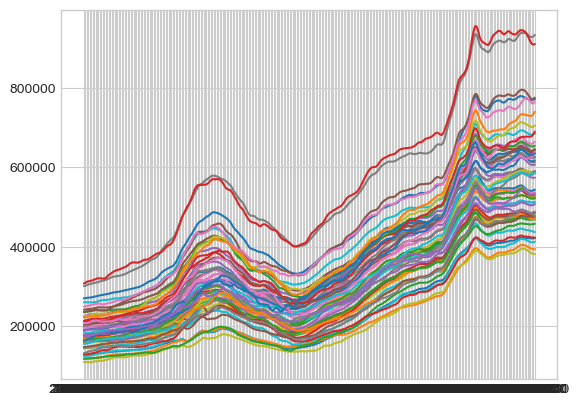

<Figure size 1400x2000 with 0 Axes>

In [488]:
# Plot a sample graph of prices over dates in transposed data for validation purposes

for region in df_PDX_final['RegionName'].unique():
    price_data = df_PDX_final[df_PDX_final['RegionName'] == region].set_index('Date')['Price']

    plt.plot(price_data.index, price_data.values, linestyle = '-')

plt.figure(figsize = (14, 20))

In [489]:
# Grouping by highest single value
#df_PDX_sorted = df_PDX_final.sort_values(['RegionName', 'Price'], ascending=[True, False])
#df_PDX_highest_per_region = df_PDX_sorted.drop_duplicates('RegionName')
#df_PDX_top_regions = df_PDX_highest_per_region.nlargest(25, 'Price')

#Grouping by highest average value
#df_PDX_highest_per_region = df_PDX_final.groupby('RegionName').agg({'Price': 'mean'}).reset_index()
#df_PDX_top_regions = df_PDX_highest_per_region.nlargest(15, 'Price')

In [490]:
# Converting values to datetime for melting
df_PDX_final['Date'] = pd.to_datetime(df_PDX_final['Date'])
df_DFW_final['Date'] = pd.to_datetime(df_DFW_final['Date'])

# Setting YYYY-MM-DD format to YYYY to be parsed better by pandas
df_PDX_final['Year'] = df_PDX_final['Date'].dt.year
df_PDX_final = df_PDX_final.drop('Date', axis = 1)

df_DFW_final['Year'] = df_DFW_final['Date'].dt.year
df_DFW_final = df_DFW_final.drop('Date', axis = 1)

In [409]:
df_PDX_final.head(7)

,RegionName,Price,Year
0,Portland,168347,2000
1,Beaverton,169846,2000
2,Gresham,158525,2000
3,Hillsboro,169252,2000
4,Tigard,204553,2000
5,Oregon City,196206,2000
6,Milwaukie,166553,2000


In [410]:
#Grouping by highest average value per year
#df_melted = df_PDX_final.reset_index(drop = True).melt(
    #id_vars=['RegionName'], 
    #var_name='Year', 
    #value_name='AvgPrice')

#Grouping highest regions manually based on region size determined using SizeRank
df_PDX_top = df_PDX_final[df_PDX_final['RegionName'].isin(['Portland', 'Beaverton', 'Gresham', 'Hillsboro', 'Tigard', 'Oregon City', 'Milwaukie'])]

#df_melted['Year'] = pd.to_datetime(df_melted['Date']).dt.year
df_PDX_avg_year = df_PDX_top.groupby(['RegionName', 'Year'])['Price'].mean().reset_index()

In [411]:
#print(df_top_regions)
print(df_PDX_avg_year)

    RegionName  Year          Price
0    Beaverton  2000  173005.909091
1    Beaverton  2001  178124.916667
2    Beaverton  2002  185904.166667
3    Beaverton  2003      193476.25
4    Beaverton  2004      205183.75
..         ...   ...            ...
177     Tigard  2021  544099.166667
178     Tigard  2022       619762.5
179     Tigard  2023      610671.25
180     Tigard  2024      617480.25
181     Tigard  2025  613971.181818

[182 rows x 3 columns]


<Figure size 1400x2000 with 0 Axes>

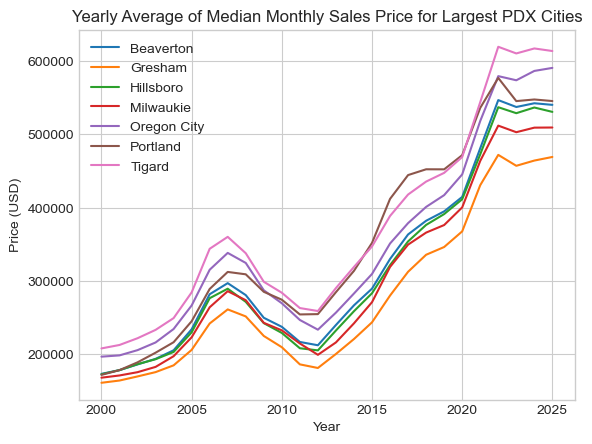

<Figure size 1400x2000 with 0 Axes>

In [412]:
# Plot tighter selection of PDX top cities that will be used throughout analysis

for region in df_PDX_avg_year['RegionName'].unique():
    price_data = df_PDX_avg_year[df_PDX_avg_year['RegionName'] == region].set_index('Year')['Price']
    
    #fit = model.fit

    plt.plot(price_data.index, price_data.values, linestyle = '-', label = region)

# Details
plt.title('Yearly Average of Median Monthly Sales Price for Largest PDX Cities')
plt.xlabel('Year')
plt.ylabel('Price (USD)')
plt.legend()

# Plot
plt.figure(figsize = (14, 20))

> From the graph of median yearly prices for the PDX area, we can see a general trend amongst all of the neighboring regions. Each area seemed to end in a similar proportional position to where it started. Tigard started as the most expensive region based on median price and is still the most expensive on average today. Gresham started as the least expensive and similarly is still the least expensive. The most significant instance of the trend being broken falls within Portland which experienced a significant amount of growth from 2015 to 2018, but later experienced the greatest decline in value in 2022-2023 when compared to its neighbors.

In [503]:
# Calculating price growth percentages between 2012 and 2025

# Setting up 
df_PDX_years = df_PDX_avg_year[df_PDX_avg_year['Year'].isin([2012, 2025])]
df_PDX_years_pivoted = df_PDX_years.pivot(index = 'RegionName', columns = 'Year', values = 'Price')

# Math pPDXtion of calculation
df_PDX_years_pivoted['GrowthRate'] = ((df_PDX_years_pivoted[2025] - df_PDX_years_pivoted[2012]) / df_PDX_years_pivoted[2012]) * 100

df_PDX_growth = df_PDX_years_pivoted.reset_index()
df_PDX_growth = df_PDX_growth.sort_values('GrowthRate', ascending = False)

df_PDX_growth.head(7)

Year,RegionName,2012,2025,GrowthRate
1,Gresham,181026.166667,469263.0,159.223851
2,Hillsboro,205073.333333,530840.636364,158.854054
3,Milwaukie,199008.666667,509494.545455,156.01626
0,Beaverton,212077.833333,540441.727273,154.831785
4,Oregon City,233339.833333,590925.545455,153.24675
6,Tigard,258827.583333,613971.181818,137.212423
5,Portland,254603.333333,545649.454545,114.313555


> The growth rates of the main PDX metro cities is somewhat surprising; while each city saw significant growth, Portland itself lags behind the neighboring suburbs by a noticable margin. Portland experienced roughly 23% less growth than the next slowest growing area, Tigard. Gresham led all cities with a growth rate of 159% over the span of 2012 to 2025 with Hillsboro, Milwaikie, Beaverton, and Oregon City all close behind with growth rates in the high-to-middling 150s.

In [504]:
# Gathering DFW Data
df_DFW_final.head(7)

,RegionName,Price,Year
0,Dallas,98127,2000
1,Fort Worth,101297,2000
2,Arlington,109114,2000
3,Plano,192109,2000
4,Garland,87251,2000
5,Frisco,236713,2000
6,McKinney,184079,2000


In [505]:
#Grouping highest regions manually based on region size determined using SizeRank
df_DFW_top = df_DFW_final[df_DFW_final['RegionName'].isin(['Dallas', 'Fort Worth', 'Arlington', 'Plano', 'Garland', 'Frisco', 'McKinney'])]

#df_melted['Year'] = pd.to_datetime(df_melted['Date']).dt.year
df_DFW_avg_year = df_DFW_top.groupby(['RegionName', 'Year'])['Price'].mean().reset_index()

In [506]:
print(df_DFW_avg_year)

    RegionName  Year          Price
0    Arlington  2000  109636.818182
1    Arlington  2001  110015.666667
2    Arlington  2002      112775.75
3    Arlington  2003  116417.833333
4    Arlington  2004  122964.666667
..         ...   ...            ...
177      Plano  2021  404236.833333
178      Plano  2022  496865.666667
179      Plano  2023  513328.333333
180      Plano  2024      527067.75
181      Plano  2025  510482.727273

[182 rows x 3 columns]


<Figure size 1400x2000 with 0 Axes>

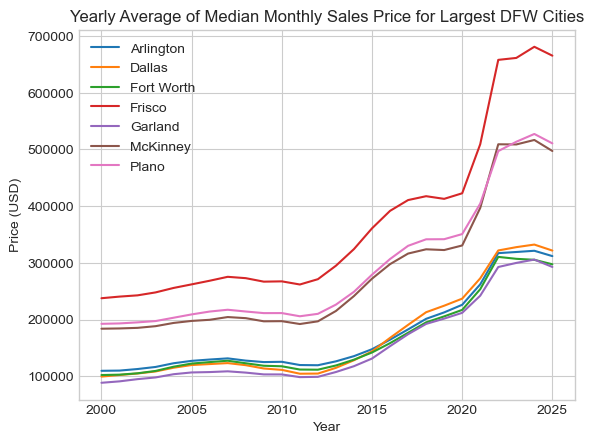

<Figure size 1400x2000 with 0 Axes>

In [507]:
# Plot tighter DFW selection

for region in df_DFW_avg_year['RegionName'].unique():
    price_data = df_DFW_avg_year[df_DFW_avg_year['RegionName'] == region].set_index('Year')['Price']
    
    #fit = model.fit

    plt.plot(price_data.index, price_data.values, linestyle = '-', label = region)

# Details
plt.title('Yearly Average of Median Monthly Sales Price for Largest DFW Cities')
plt.xlabel('Year')
plt.ylabel('Price (USD)')
plt.legend()

# Plot
plt.figure(figsize = (14, 20))

> While the general trend of increasing median yearly price is similar to the PDX data, we can immediately see some very obvious differences between these two regional selections of data. From the beginning, it is obvious that the regions in DFW have more variety in their perspective value, this also inspires a second point where just over half of the regions being identified all have substantially lower initial costs than the PDX region. Dallas, Ft. Worth, Arlington, and Garland all start within a few percentage points of $100,000.

> The next substantial difference can be seen in the trend itself. The DFW region did not experience a drastic devaluation post-2008 like the PDX area did. Finally, Frisco finishes with the highest valuation amongst all cities in 2025.

In [508]:
# Calculating price growth percentages between 2012 and 2025

# Setting up 
df_DFW_years = df_DFW_avg_year[df_DFW_avg_year['Year'].isin([2012, 2025])]
df_DFW_years_pivoted = df_DFW_years.pivot(index = 'RegionName', columns = 'Year', values = 'Price')

# Math portion of calculation
df_DFW_years_pivoted['GrowthRate'] = ((df_DFW_years_pivoted[2025] - df_DFW_years_pivoted[2012]) / df_DFW_years_pivoted[2012]) * 100

df_DFW_growth = df_DFW_years_pivoted.reset_index()
df_DFW_growth = df_DFW_growth.sort_values('GrowthRate', ascending = False)

df_DFW_growth.head(7)

Year,RegionName,2012,2025,GrowthRate
1,Dallas,104764.25,321544.454545,206.921927
4,Garland,99000.5,292692.909091,195.64791
2,Fort Worth,111583.5,297366.272727,166.496635
0,Arlington,119462.5,311787.636364,160.992057
5,McKinney,196850.083333,497044.363636,152.498935
3,Frisco,271116.333333,665051.818182,145.301273
6,Plano,210060.083333,510482.727273,143.017483


> As expected from the median yearly values being different from the PDX region, DFW's growth rates also present some substantial differences. There is a higher floor of growth rates with the lowest being Plano and Frisco at 143-145% and also a higher ceiling with Garland and Dallas being between 196-207%, and a healthy middle chunk of regions as well.

> An additional key note on the DFW region, however, would be that the growth rate is almost perfectly inverted with each of the substantially more expensive regions experiencing much less growth on average than the cheaper areas. Although PDX has a generally similar trend, it is significantly less pronounced and Hillsboro, Beaverton, and Oregon City all stand out as relative exceptions to the rule presented within DFW.

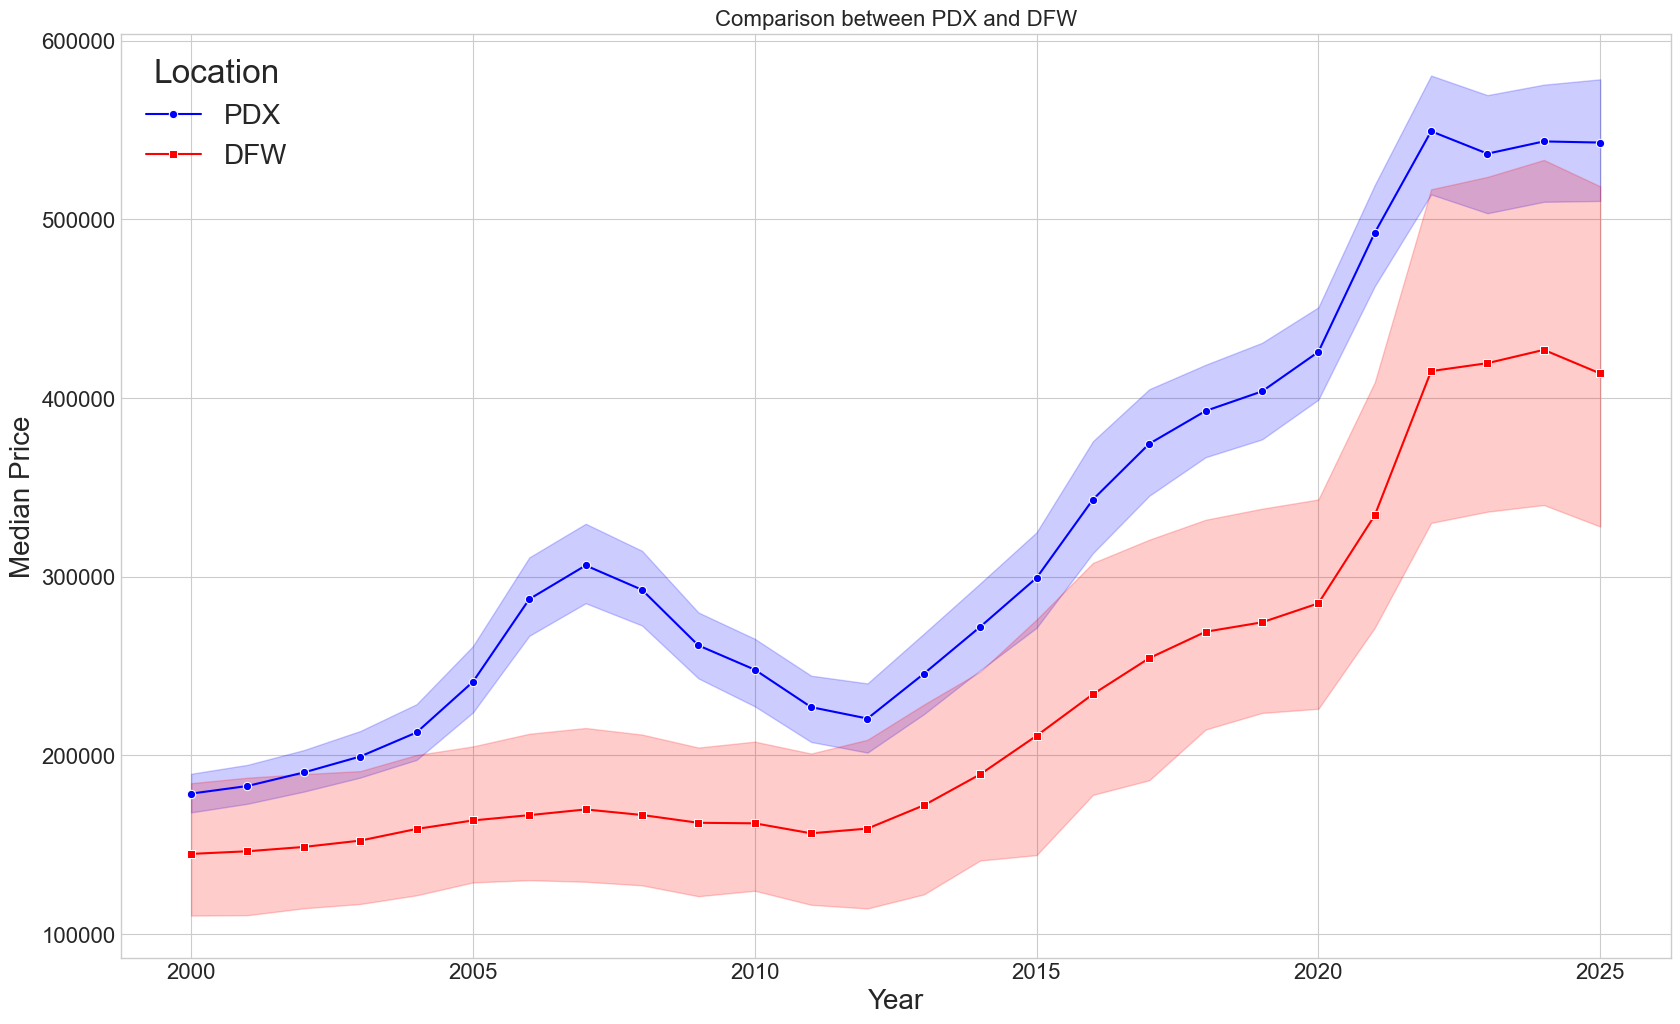

In [509]:
# Plotting PDX & DFW median prices per year against each other for better visual inspection
fig, ax = plt.subplots(figsize=(20, 12))

# Setting PDX/DFW lines
sns.lineplot(data=df_PDX_avg_year, x = 'Year', y = 'Price', color = 'blue', marker = 'o', ax = ax, label = 'PDX')
sns.lineplot(data=df_DFW_avg_year, x = 'Year', y = 'Price', color = 'red', marker = 's', ax = ax, label = 'DFW')

# Details
plt.title('Comparison between PDX and DFW', fontsize=16)
plt.xlabel('Year', fontsize=20)
plt.ylabel('Median Price', fontsize=20) 
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(title='Location', fontsize=20, title_fontsize=24)

# Plotting
plt.show()

> This graph further summarizes the trends highlighted earlier in the analysis. DFW experienced massive growth, but not enough to overtake PDX which also experienced its own substantial growth trend.

In [510]:
# Statistical Significance Testing

# Set Price frames
pdx_prices = df_PDX_avg_year['Price']
dfw_prices = df_DFW_avg_year['Price']

# T-test from scipy - stats
t_stat, p_value = stats.ttest_ind(pdx_prices, dfw_prices, equal_var = False)

print(f"T-stat: {t_stat:.4f}")
print(f"P-value: {p_value:.14f}")

T-stat: 7.3404
P-value: 0.00000000000142


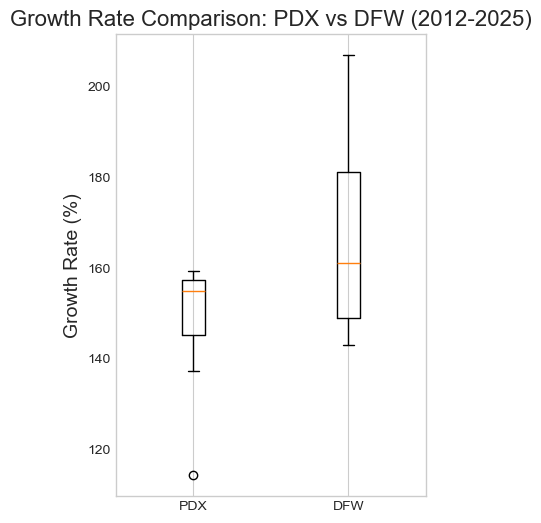

In [511]:
# Box plot to compare growth rates
plt.figure(figsize=(4, 6))

# Load data
growth_data = [df_PDX_growth['GrowthRate'], df_DFW_growth['GrowthRate']]

# Details
plt.boxplot(growth_data, tick_labels=['PDX', 'DFW'])
plt.title('Growth Rate Comparison: PDX vs DFW (2012-2025)', fontsize=16)
plt.ylabel('Growth Rate (%)', fontsize=14)
plt.grid(axis='y')

In [512]:
# T-Test for city growth rates

# Set Growth frames
pdx_growth = df_PDX_growth['GrowthRate']
dfw_growth = df_DFW_growth['GrowthRate']

# T-Test from scipy - stats 
t_stat, p_value = stats.ttest_ind(pdx_growth, dfw_growth, equal_var = False)

print(f"T-stat: {t_stat:.4f}")
print(f"P-value: {p_value:.4f}")

T-stat: -1.7381
P-value: 0.1116


> Finally, two separate T-Tests were performed along with calculating the p-values for both the median home value and the growth rates between the two regions to attempt to define which region would be the preferred investment opportunity. Regarding the median home value, the returned t-stat value of 7.34 and p-value of 0.00 explain the relationship between the median home price and the overwhelming one-sided nature of the association. Outside of a small percentage of instances where, like Frisco, DFW values creep up to the bottom portion of PDX region values, PDX median home prices across the board remain convincingly higher.

> Growth rates between the two regions have a markedly different relationship, however. With a t-stat value of -1.74 when comparing PDX growth to DFW, it is clear that DFW's mean growth rate is higher than that of PDX. That being said, a P-value of 0.11 falls outside the typically accepted alpha of 0.05, indicating that the relationship between the regions is not statistically significant. This would likely be caused by the PDX region also experiencing significant growth over the same time period, ultimately making it difficult to convincingly describe DFW's growth as the superior option.